In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

zip_path = "/content/drive/MyDrive/Metal_Defect_Project/dataset_for_colab.zip"

print("ZIP exists:", os.path.exists(zip_path))

ZIP exists: True


In [3]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Metal_Defect_Project/dataset_for_colab.zip"
extract_path = "/content/metal_defect_project"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Folders:", os.listdir(extract_path))

Dataset extracted successfully!
Folders: ['dataset\\masks\\img_05_425505900_01176.png', 'dataset\\raw\\label\\img_05_4406645900_00038.xml', 'dataset\\raw\\label\\img_01_425005700_00298.xml', 'dataset\\raw\\defect\\images\\images\\silk_spot\\img_01_425005700_00395.jpg', 'dataset\\masks\\img_08_425508200_00033.png', 'dataset\\masks\\img_02_SIS001491_00280.png', 'dataset\\raw\\images\\silk_spot\\img_04_SIS001577_00040.jpg', 'dataset\\raw\\images\\silk_spot\\img_07_4406645900_00781.jpg', 'dataset\\raw\\images\\silk_spot\\img_01_425005700_00379.jpg', 'dataset\\raw\\images\\silk_spot\\img_07_4406743300_00039.jpg', 'dataset\\masks\\img_06_425508300_00929.png', 'dataset\\raw\\label\\img_07_3436814000_00693.xml', 'dataset\\raw\\defect\\images\\images\\silk_spot\\img_08_4406743300_00450.jpg', 'dataset\\raw\\label\\img_07_4406645900_00570.xml', 'dataset\\raw\\images\\waist folding\\img_07_4405133600_00046.jpg', 'dataset\\raw\\label\\img_01_425005700_00337.xml', 'dataset\\raw\\images\\inclusion\\i

In [4]:
import zipfile

zip_path = "/content/drive/MyDrive/Metal_Defect_Project/dataset_for_colab.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for item in z.infolist()[:30]:
        print(repr(item.filename), "| Directory:", item.is_dir())

'dataset\\raw\\' | Directory: False
'dataset\\masks\\debur_img_001.png' | Directory: False
'dataset\\masks\\debur_img_002.png' | Directory: False
'dataset\\masks\\debur_img_003.png' | Directory: False
'dataset\\masks\\debur_img_004.png' | Directory: False
'dataset\\masks\\debur_img_005.png' | Directory: False
'dataset\\masks\\debur_img_006.png' | Directory: False
'dataset\\masks\\debur_img_007.png' | Directory: False
'dataset\\masks\\debur_img_008.png' | Directory: False
'dataset\\masks\\debur_img_009.png' | Directory: False
'dataset\\masks\\debur_img_010.png' | Directory: False
'dataset\\masks\\debur_img_011.png' | Directory: False
'dataset\\masks\\debur_img_012.png' | Directory: False
'dataset\\masks\\debur_img_013.png' | Directory: False
'dataset\\masks\\debur_img_014.png' | Directory: False
'dataset\\masks\\debur_img_015.png' | Directory: False
'dataset\\masks\\debur_img_016.png' | Directory: False
'dataset\\masks\\debur_img_017.png' | Directory: False
'dataset\\masks\\debur_img_01

In [5]:
import zipfile
import os
import shutil

zip_path = "/content/drive/MyDrive/Metal_Defect_Project/dataset_for_colab.zip"
extract_path = "/content/metal_defect_fixed"

# Start with a clean extraction folder
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path)

with zipfile.ZipFile(zip_path, "r") as z:
    for item in z.infolist():

        name = item.filename.replace("\\", "/")
        is_folder = item.is_dir() or name.endswith("/")

        name = name.strip("/")

        if not name:
            continue

        destination = os.path.join(extract_path, *name.split("/"))

        if is_folder:
            os.makedirs(destination, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(destination), exist_ok=True)

            with z.open(item) as source:
                with open(destination, "wb") as target:
                    shutil.copyfileobj(source, target)

print("Extraction completed successfully!")

Extraction completed successfully!


In [6]:
import os

base = "/content/metal_defect_fixed/dataset"

print("Images folder:", os.path.exists(base + "/raw/images"))
print("Masks folder:", os.path.exists(base + "/masks"))
print("CSV exists:", os.path.exists(base + "/processed/annotations.csv"))

print("Mask count:", len(os.listdir(base + "/masks")))

Images folder: True
Masks folder: True
CSV exists: True
Mask count: 1075


In [7]:

import os
import cv2
import numpy as np
import pandas as pd

BASE = "/content/metal_defect_fixed/dataset"
CSV_PATH = os.path.join(BASE, "processed", "annotations.csv")
IMAGE_ROOT = "/content/metal_defect_fixed"

# Save bounding-box-based masks separately
GENERATED_MASK_DIR = os.path.join(BASE, "generated_masks_bbox")
os.makedirs(GENERATED_MASK_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

generated_count = 0
failed_images = []

for name, group in df.groupby("image_name"):

    image_path = os.path.join(
        IMAGE_ROOT,
        str(group.iloc[0]["image_path"])
    )

    image = cv2.imread(image_path)

    if image is None:
        failed_images.append(name)
        continue

    actual_h, actual_w = image.shape[:2]

    # Black background
    mask = np.zeros(
        (actual_h, actual_w),
        dtype=np.uint8
    )

    for _, row in group.iterrows():

        # Scale annotation coordinates to actual image size
        sx = actual_w / float(row["width"])
        sy = actual_h / float(row["height"])

        x1 = int(round(row["xmin"] * sx))
        y1 = int(round(row["ymin"] * sy))
        x2 = int(round(row["xmax"] * sx))
        y2 = int(round(row["ymax"] * sy))

        # Keep coordinates inside image
        x1 = np.clip(x1, 0, actual_w - 1)
        y1 = np.clip(y1, 0, actual_h - 1)
        x2 = np.clip(x2, 0, actual_w - 1)
        y2 = np.clip(y2, 0, actual_h - 1)

        # Draw filled defect bounding box
        if x2 > x1 and y2 > y1:
            cv2.rectangle(
                mask,
                (x1, y1),
                (x2, y2),
                255,
                thickness=-1
            )

    mask_name = os.path.splitext(str(name))[0] + ".png"

    cv2.imwrite(
        os.path.join(GENERATED_MASK_DIR, mask_name),
        mask
    )

    generated_count += 1

print("Bounding-box mask generation completed!")
print("Generated masks:", generated_count)
print("Failed images:", len(failed_images))
print("Output folder:", GENERATED_MASK_DIR)

if failed_images:
    print("Failed image examples:", failed_images[:10])


Bounding-box mask generation completed!
Generated masks: 1075
Failed images: 0
Output folder: /content/metal_defect_fixed/dataset/generated_masks_bbox


In [8]:

import os
import cv2
import pandas as pd
import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# Paths
BASE = "/content/metal_defect_fixed/dataset"
IMAGE_ROOT = "/content/metal_defect_fixed"

CSV_PATH = os.path.join(BASE, "processed", "annotations.csv")
GENERATED_MASK_DIR = os.path.join(BASE, "generated_masks_bbox")

# Settings
IMAGE_SIZE = 256
BATCH_SIZE = 4

# Read annotations
df = pd.read_csv(CSV_PATH)

# Get unique image names
image_names = df["image_name"].dropna().unique().tolist()

# Split dataset: 70% train, 15% validation, 15% test
train_names, temp_names = train_test_split(
    image_names,
    test_size=0.30,
    random_state=42
)

val_names, test_names = train_test_split(
    temp_names,
    test_size=0.50,
    random_state=42
)

# OpenCV CLAHE enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Dataset class
class MetalDataset(Dataset):

    def __init__(self, names):
        self.names = names

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):

        name = self.names[idx]

        rows = df[df["image_name"] == name]

        image_path = os.path.join(
            IMAGE_ROOT,
            str(rows.iloc[0]["image_path"])
        )

        mask_name = os.path.splitext(str(name))[0] + ".png"

        mask_path = os.path.join(
            GENERATED_MASK_DIR,
            mask_name
        )

        if not os.path.exists(image_path):
            raise FileNotFoundError(image_path)

        if not os.path.exists(mask_path):
            raise FileNotFoundError(mask_path)

        # Read image and mask
        image = np.array(
            Image.open(image_path).convert("RGB")
        )

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        # Resize
        image = cv2.resize(
            image,
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        mask = cv2.resize(
            mask,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        # Binary mask
        mask = np.where(mask > 0, 255, 0).astype(np.uint8)

        # CLAHE enhancement using OpenCV
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = clahe.apply(lab[:, :, 0])
        image = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

        # Normalize
        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        # Convert to PyTorch tensors
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


# Create datasets
train_dataset = MetalDataset(train_names)
val_dataset = MetalDataset(val_names)
test_dataset = MetalDataset(test_names)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Check dataset
print("Dataset loading completed!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Mask values:", torch.unique(masks))


Dataset loading completed!
Training images: 752
Validation images: 161
Testing images: 162
Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])
Mask values: tensor([0., 1.])


Image: debur_img_001.png | White pixels: 4263 | Defect candidate area: 5.13%
Image: debur_img_002.jpg | White pixels: 27068 | Defect candidate area: 7.88%
Image: debur_img_003.jpg | White pixels: 11880 | Defect candidate area: 5.76%
Image: debur_img_004.jpg | White pixels: 9828 | Defect candidate area: 12.97%
Image: debur_img_005.jpg | White pixels: 8004 | Defect candidate area: 12.07%
Image: debur_img_006.png | White pixels: 3591 | Defect candidate area: 9.39%
Image: debur_img_007.png | White pixels: 11484 | Defect candidate area: 31.14%
Image: debur_img_008.png | White pixels: 1716 | Defect candidate area: 6.32%


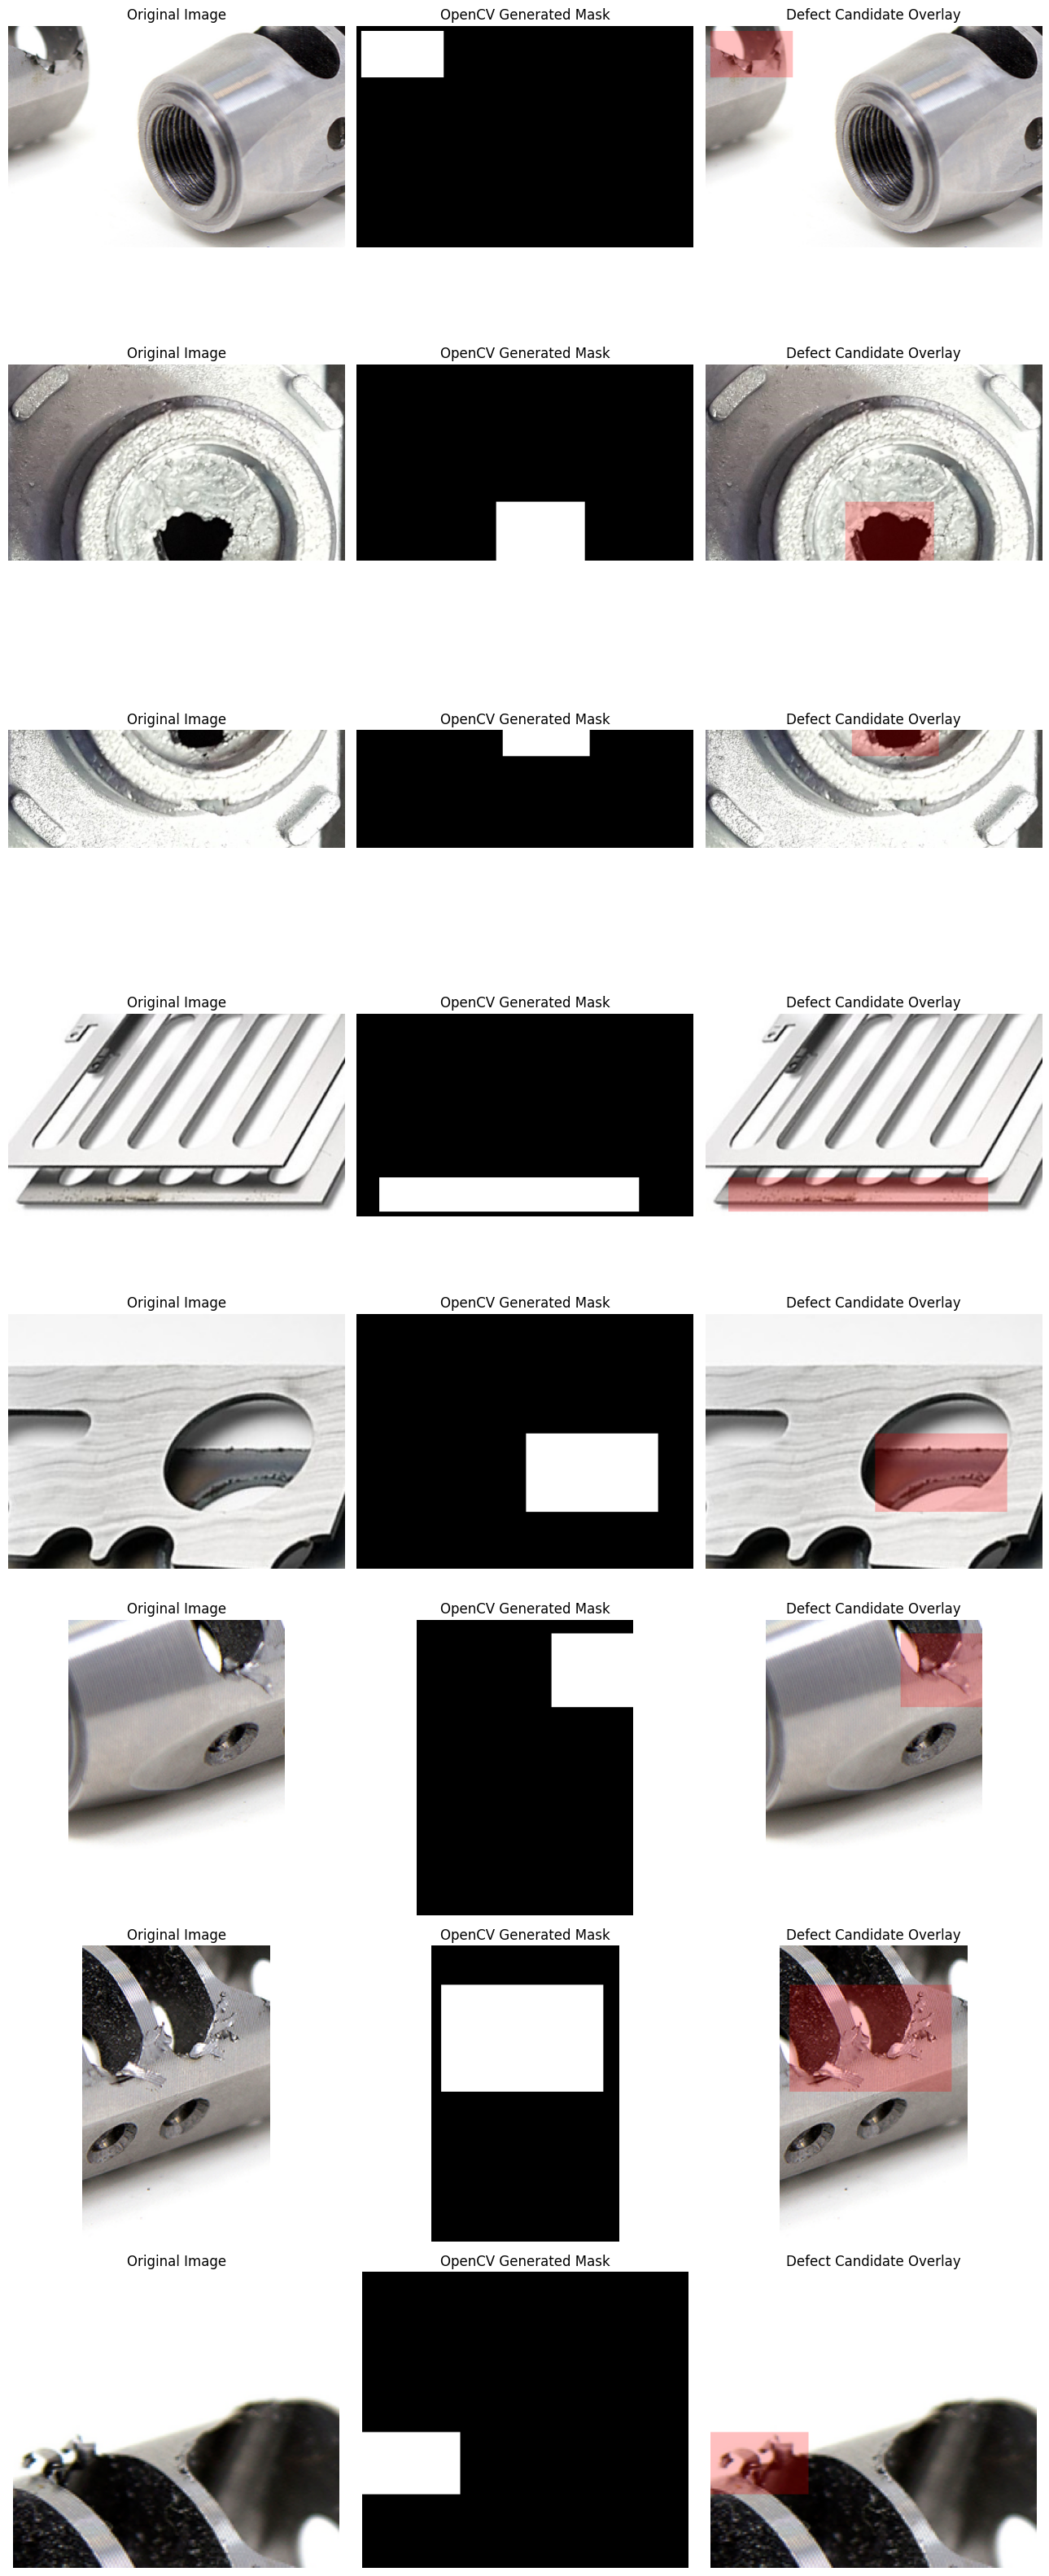

In [9]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load annotations
df = pd.read_csv(CSV_PATH)

# Select first 8 unique images
sample_names = df["image_name"].dropna().unique()[:8]

# Create visualization layout
fig, axes = plt.subplots(
    len(sample_names),
    3,
    figsize=(13, 4 * len(sample_names))
)

# Handle single image case
if len(sample_names) == 1:
    axes = axes.reshape(1, 3)

for i, name in enumerate(sample_names):

    rows = df[df["image_name"] == name]

    # Image path
    image_path = os.path.join(
        IMAGE_ROOT,
        str(rows.iloc[0]["image_path"])
    )

    # Generated mask path
    mask_path = os.path.join(
        GENERATED_MASK_DIR,
        os.path.splitext(str(name))[0] + ".png"
    )

    # Check whether image exists
    if not os.path.exists(image_path):
        print("Image not found:", image_path)
        continue

    # Check whether mask exists
    if not os.path.exists(mask_path):
        print("Mask not found:", mask_path)
        continue

    # Read original image
    image = cv2.imread(image_path)

    if image is None:
        print("Unable to read image:", image_path)
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Read generated mask
    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        print("Unable to read mask:", mask_path)
        continue

    # Check mask dimensions
    if mask.shape != image.shape[:2]:
        mask = cv2.resize(
            mask,
            (image.shape[1], image.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    # Count detected pixels
    white_pixels = np.count_nonzero(mask > 0)
    total_pixels = mask.size
    defect_percentage = (white_pixels / total_pixels) * 100

    print(
        f"Image: {name} | "
        f"White pixels: {white_pixels} | "
        f"Defect candidate area: {defect_percentage:.2f}%"
    )

    # Create overlay
    overlay = image.copy()

    # Highlight only detected defect pixels
    overlay[mask > 0] = [255, 0, 0]

    # Blend original image and highlighted regions
    overlay = cv2.addWeighted(
        image,
        0.75,
        overlay,
        0.25,
        0
    )

    # Display original image
    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    # Display generated mask
    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("OpenCV Generated Mask")

    # Display defect overlay
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Defect Candidate Overlay")

    # Hide axes
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

sample = torch.randn(2, 3, 256, 256).to(device)
output = model(sample)

print("Device:", device)
print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Input shape: torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 1, 256, 256])
Model parameters: 482033


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim

# Binary Cross Entropy loss
bce_loss = nn.BCEWithLogitsLoss()

# Adam optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

def dice_loss(predictions, targets):
    predictions = torch.sigmoid(predictions)

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (predictions * targets).sum(dim=1)

    dice = (
        2.0 * intersection + 1e-7
    ) / (
        predictions.sum(dim=1) +
        targets.sum(dim=1) + 1e-7
    )

    return 1 - dice.mean()

def combined_loss(predictions, targets):
    return bce_loss(predictions, targets) + dice_loss(
        predictions, targets
    )

print("Loss function: BCE + Dice Loss")
print("Optimizer: Adam")
print("Learning rate: 0.001")

Loss function: BCE + Dice Loss
Optimizer: Adam
Learning rate: 0.001


In [13]:

import os
import torch
from tqdm.notebook import tqdm

# =====================================
# 1. TRAINING SETTINGS
# =====================================

EPOCHS = 50

best_val_loss = float("inf")

# Early stopping
patience = 10
epochs_without_improvement = 0

# Minimum improvement required
min_delta = 0.0001

# Save model separately
checkpoint_path = (
    "/content/drive/MyDrive/Metal_Defect_Project/"
    "best_unet_opencv_improved.pth"
)

os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

# Learning rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

# Store loss history
train_losses = []
val_losses = []

# =====================================
# 2. START TRAINING
# =====================================

for epoch in range(EPOCHS):

    # -----------------------------
    # TRAINING
    # -----------------------------

    model.train()
    train_loss = 0.0

    for images, masks in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1} Training"
    ):

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -----------------------------
    # VALIDATION
    # -----------------------------

    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = combined_loss(outputs, masks)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    # Store losses
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # -----------------------------
    # LEARNING RATE UPDATE
    # -----------------------------

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # -----------------------------
    # DISPLAY RESULTS
    # -----------------------------

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Learning Rate: {current_lr:.7f}")

    # -----------------------------
    # SAVE BEST MODEL
    # -----------------------------

    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        epochs_without_improvement = 0

        print("Best model saved!")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{patience}"
        )

    # -----------------------------
    # EARLY STOPPING
    # -----------------------------

    if epochs_without_improvement >= patience:

        print("\nEarly stopping triggered!")
        print("Training stopped because validation loss did not improve.")

        break

# =====================================
# 3. TRAINING COMPLETED
# =====================================

print("\n========== TRAINING COMPLETED ==========")

print("Best validation loss:", best_val_loss)

print("Best model saved at:", checkpoint_path)

# =====================================
# 4. LOAD BEST MODEL
# =====================================

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best U-Net model loaded successfully!")


Epoch 1 Training:   0%|          | 0/188 [00:00<?, ?it/s]


Epoch 1/50
Training Loss: 1.2922
Validation Loss: 1.2418
Learning Rate: 0.0010000
Best model saved!


Epoch 2 Training:   0%|          | 0/188 [00:00<?, ?it/s]


Epoch 2/50
Training Loss: 1.2426
Validation Loss: 1.2289
Learning Rate: 0.0010000
Best model saved!


Epoch 3 Training:   0%|          | 0/188 [00:00<?, ?it/s]


Epoch 3/50
Training Loss: 1.2191
Validation Loss: 1.2070
Learning Rate: 0.0010000
Best model saved!


... (90 outputs left out)

Epoch 49 Training:   0%|          | 0/188 [00:00<?, ?it/s]


Epoch 49/50
Training Loss: 0.6179
Validation Loss: 0.7174
Learning Rate: 0.0010000
No improvement: 3/10


Epoch 50 Training:   0%|          | 0/188 [00:00<?, ?it/s]


Epoch 50/50
Training Loss: 0.6113
Validation Loss: 0.7088
Learning Rate: 0.0005000
No improvement: 4/10

========== TRAINING COMPLETED ==========
Best validation loss: 0.7023432661847371
Best model saved at: /content/drive/MyDrive/Metal_Defect_Project/best_unet_opencv_improved.pth
Best U-Net model loaded successfully!


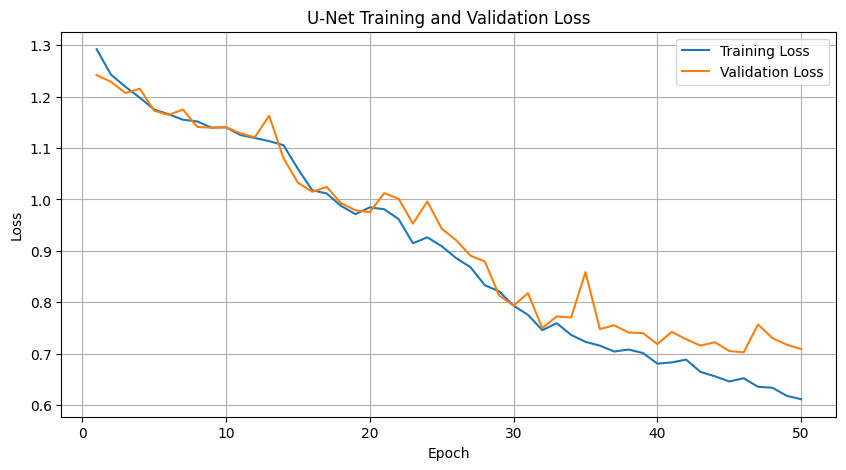

In [14]:

import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


In [15]:
model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)
model.eval()

print("Best trained model loaded successfully!")

Best trained model loaded successfully!


In [16]:

import numpy as np
import torch
from tqdm.notebook import tqdm

model.eval()

test_dice_scores = []
test_iou_scores = []

with torch.no_grad():

    for images, masks in tqdm(test_loader, desc="Testing U-Net"):

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        # Raw U-Net prediction at threshold 0.5
        predictions = (
            torch.sigmoid(outputs) > 0.5
        ).float()

        for pred, target in zip(predictions, masks):

            intersection = (pred * target).sum().item()

            pred_sum = pred.sum().item()
            target_sum = target.sum().item()

            dice = (
                2 * intersection + 1e-7
            ) / (
                pred_sum + target_sum + 1e-7
            )

            union = pred_sum + target_sum - intersection

            iou = (
                intersection + 1e-7
            ) / (
                union + 1e-7
            )

            test_dice_scores.append(dice)
            test_iou_scores.append(iou)

print("\n========== UNSEEN TEST RESULTS ==========")

print(
    "Test Dice Score:",
    round(np.mean(test_dice_scores), 4)
)

print(
    "Test IoU Score:",
    round(np.mean(test_iou_scores), 4)
)


Testing U-Net:   0%|          | 0/41 [00:00<?, ?it/s]


========== UNSEEN TEST RESULTS ==========
Test Dice Score: 0.6044
Test IoU Score: 0.4712


In [25]:

import torch

model.eval()

TP = 0
TN = 0
FP = 0
FN = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        predictions = (
            torch.sigmoid(outputs) > 0.5
        ).float()

        TP += ((predictions == 1) & (masks == 1)).sum().item()
        TN += ((predictions == 0) & (masks == 0)).sum().item()
        FP += ((predictions == 1) & (masks == 0)).sum().item()
        FN += ((predictions == 0) & (masks == 1)).sum().item()

# Calculate metrics
accuracy = (TP + TN) / (TP + TN + FP + FN + 1e-7)

precision = TP / (TP + FP + 1e-7)

recall = TP / (TP + FN + 1e-7)

f1_score = (
    2 * precision * recall
) / (precision + recall + 1e-7)

dice = (
    2 * TP
) / (2 * TP + FP + FN + 1e-7)

iou = (
    TP
) / (TP + FP + FN + 1e-7)

print("========== TEST PERFORMANCE ==========")
print(f"Pixel Accuracy : {accuracy * 100:.2f}%")
print(f"Precision      : {precision * 100:.2f}%")
print(f"Recall         : {recall * 100:.2f}%")
print(f"F1 Score       : {f1_score * 100:.2f}%")
print(f"Dice Score     : {dice * 100:.2f}%")
print(f"IoU Score      : {iou * 100:.2f}%")


========== TEST PERFORMANCE ==========
Pixel Accuracy : 89.68%
Precision      : 62.67%
Recall         : 72.07%
F1 Score       : 67.04%
Dice Score     : 67.04%
IoU Score      : 50.42%


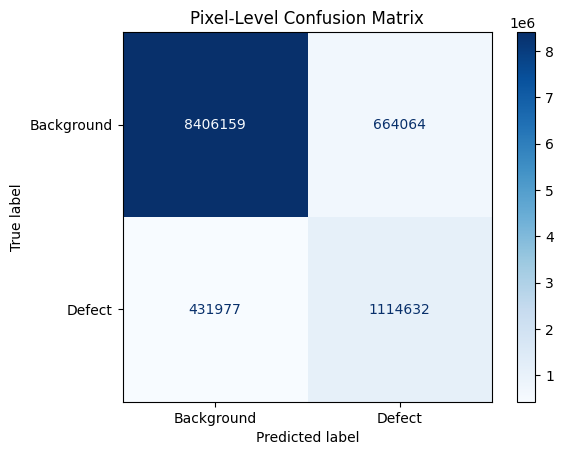

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = np.array([
    [TN, FP],
    [FN, TP]
])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Defect"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Pixel-Level Confusion Matrix")
plt.show()

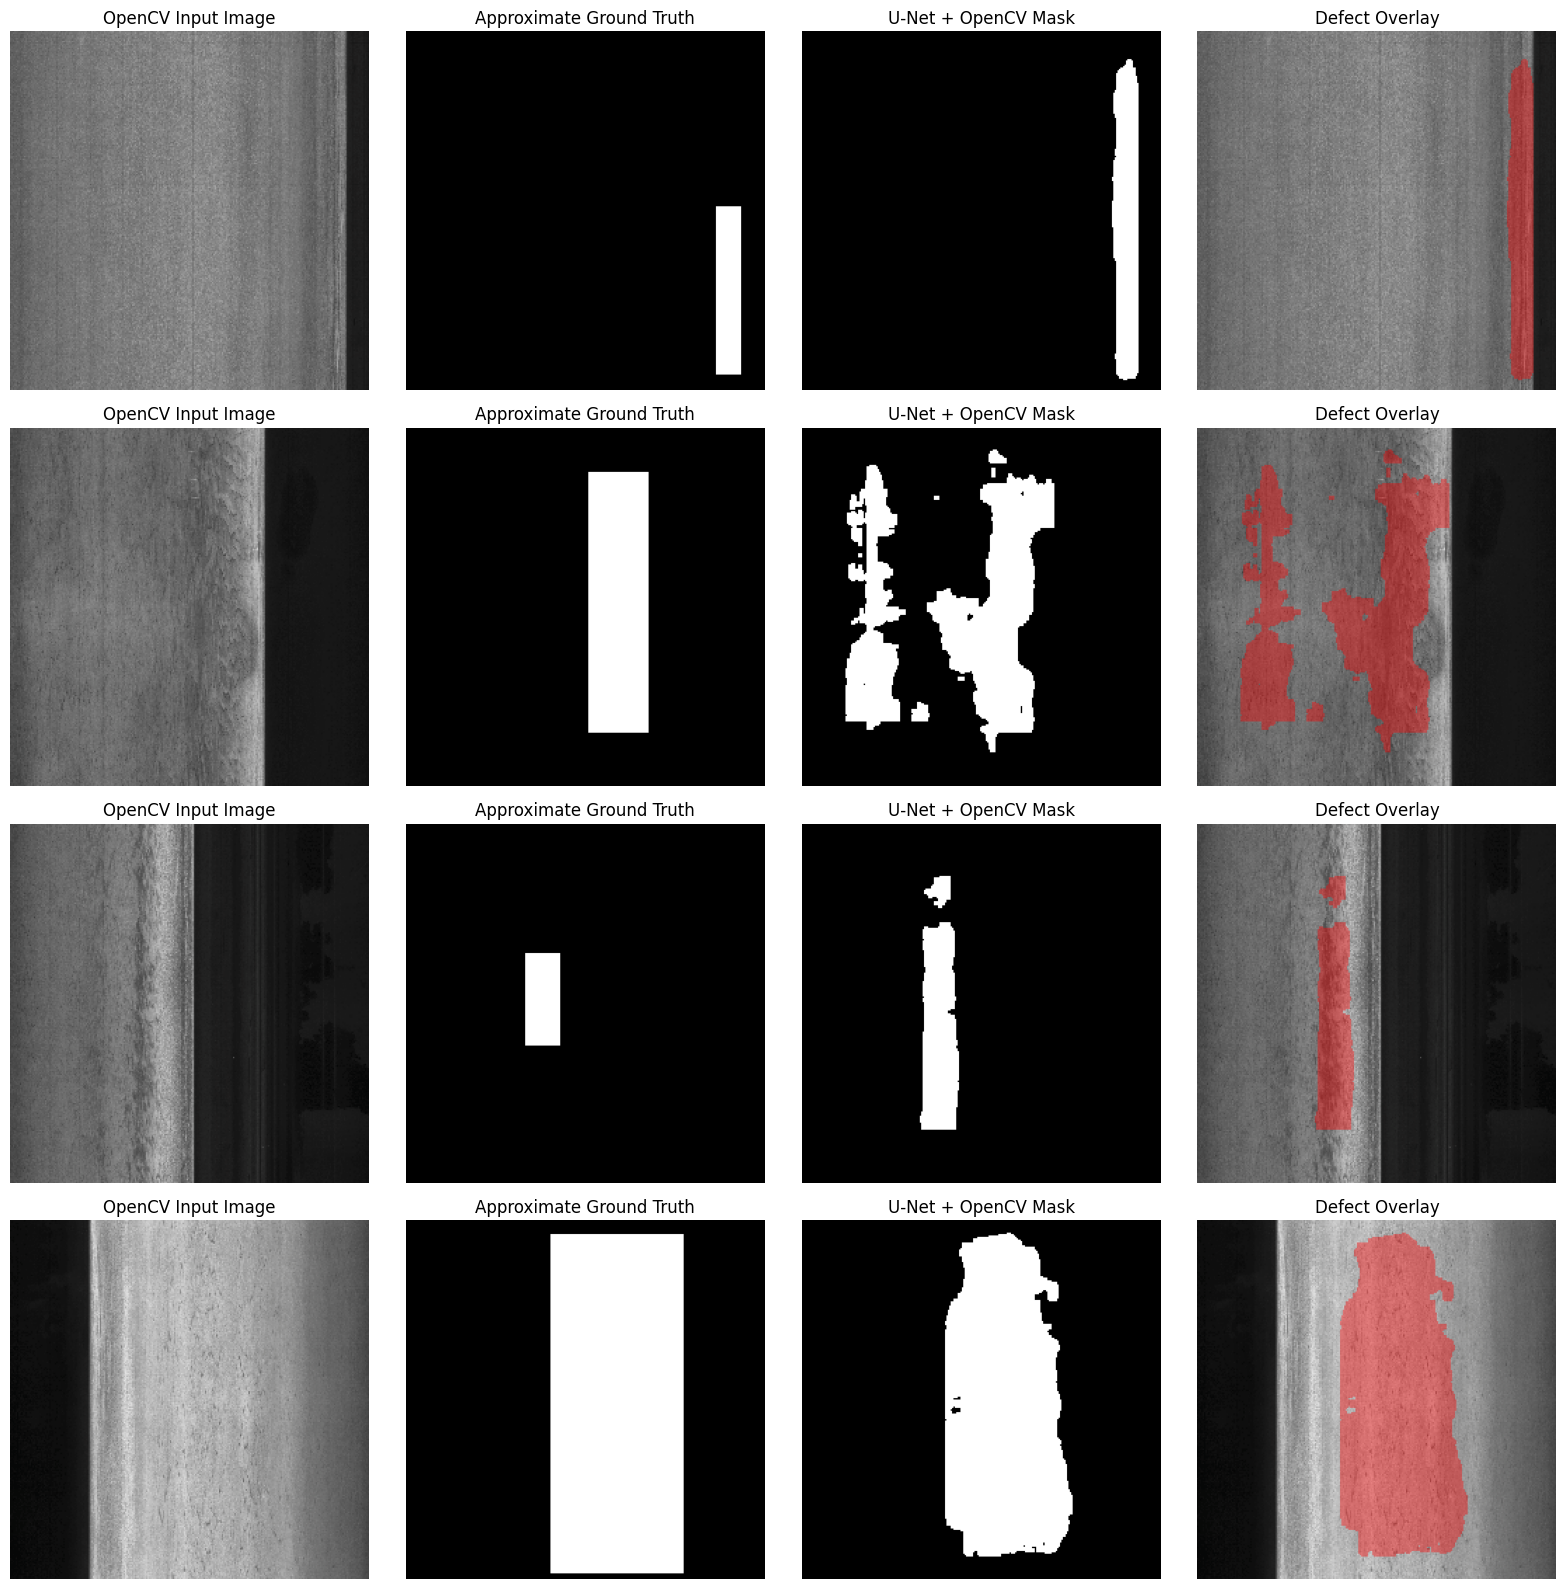

In [23]:

import matplotlib.pyplot as plt
import cv2
import numpy as np
import torch

model.eval()

images, masks = next(iter(test_loader))

n = min(4, len(images))

fig, axes = plt.subplots(n, 4, figsize=(16, 4*n))

if n == 1:
    axes = axes.reshape(1, 4)

with torch.no_grad():

    outputs = model(images[:n].to(device))
    probabilities = torch.sigmoid(outputs)

for i in range(n):

    # OpenCV-preprocessed input image
    image = images[i].permute(1, 2, 0).numpy()
    image = (image * 255).clip(0, 255).astype(np.uint8)

    # Ground-truth approximate mask
    target = masks[i, 0].numpy()

    # U-Net prediction
    pred = probabilities[i, 0].cpu().numpy()

    binary_mask = (pred > 0.5).astype(np.uint8) * 255

    # OpenCV post-processing
    kernel = np.ones((3, 3), np.uint8)

    clean_mask = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    # Red overlay
    overlay = image.copy()
    overlay[clean_mask > 0] = [255, 0, 0]

    overlay = cv2.addWeighted(
        image, 0.6,
        overlay, 0.4,
        0
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("OpenCV Input Image")

    axes[i, 1].imshow(target, cmap="gray")
    axes[i, 1].set_title("Approximate Ground Truth")

    axes[i, 2].imshow(clean_mask, cmap="gray")
    axes[i, 2].set_title("U-Net + OpenCV Mask")

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Defect Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [18]:
import numpy as np
from tqdm.notebook import tqdm

dice_scores = []
iou_scores = []

with torch.no_grad():
    for images, masks in tqdm(val_loader):

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        predictions = (torch.sigmoid(outputs) > 0.5).float()

        for pred, target in zip(predictions, masks):

            intersection = (pred * target).sum().item()
            pred_sum = pred.sum().item()
            target_sum = target.sum().item()

            dice = (2 * intersection + 1e-7) / (
                pred_sum + target_sum + 1e-7
            )

            union = pred_sum + target_sum - intersection

            iou = (intersection + 1e-7) / (union + 1e-7)

            dice_scores.append(dice)
            iou_scores.append(iou)

print("Mean Dice Score:", round(np.mean(dice_scores), 4))
print("Mean IoU Score:", round(np.mean(iou_scores), 4))

  0%|          | 0/41 [00:00<?, ?it/s]

Mean Dice Score: 0.6249
Mean IoU Score: 0.4914


In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)

OpenCV Version: 4.14.0


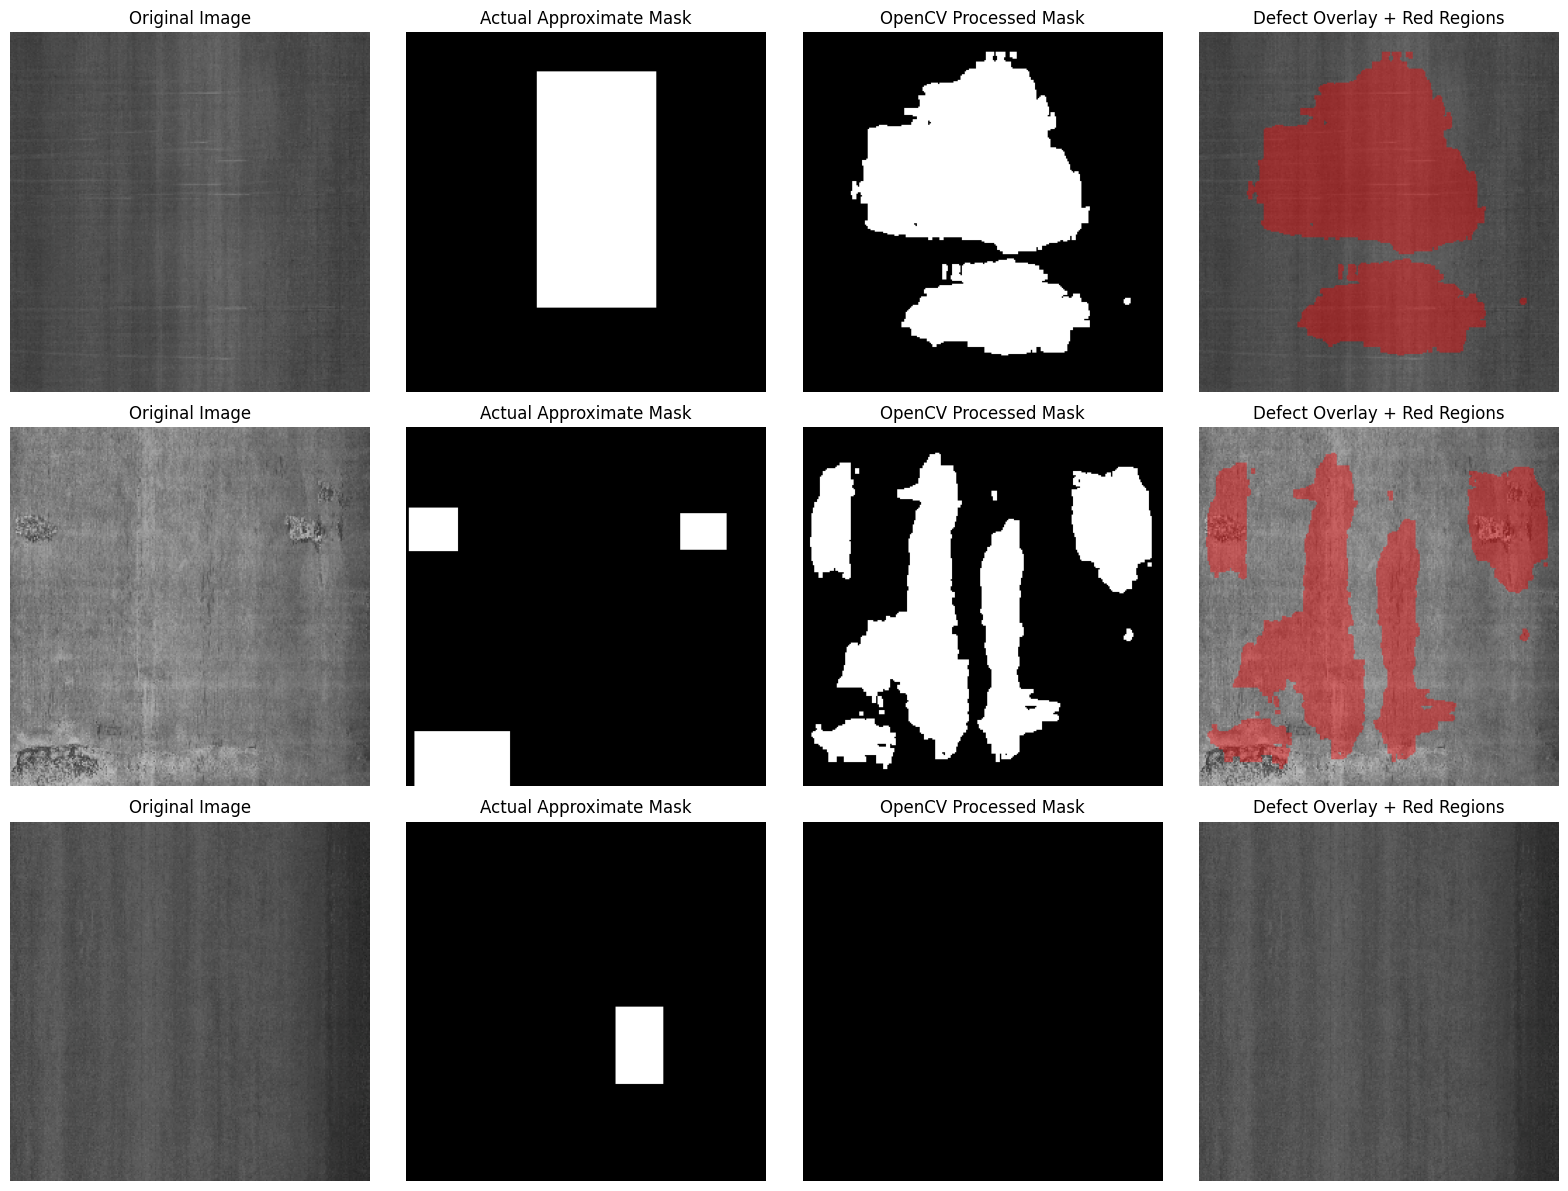

In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Get validation images
images, masks = next(iter(val_loader))

model.eval()

with torch.no_grad():
    outputs = model(images.to(device))
    probabilities = torch.sigmoid(outputs)

n = min(3, len(images))

fig, axes = plt.subplots(n, 4, figsize=(16, 4*n))

# Handle single-image batches
if n == 1:
    axes = axes.reshape(1, 4)

for i in range(n):

    # Original image
    image = images[i].permute(1, 2, 0).numpy()
    image = (image * 255).clip(0, 255).astype(np.uint8)

    # Actual mask
    target = masks[i, 0].numpy()

    # U-Net prediction
    pred = probabilities[i, 0].cpu().numpy()

    # Convert prediction into binary mask
    binary_mask = (pred > 0.5).astype(np.uint8) * 255

    # OpenCV: Remove small noise
    kernel = np.ones((3, 3), np.uint8)

    clean_mask = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    # OpenCV: Find defect contours
    contours, _ = cv2.findContours(
        clean_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Draw red defect boundaries
    output = image.copy()

    cv2.drawContours(
        output,
        contours,
        -1,
        (255, 0, 0),
        2
    )

    # Draw green bounding boxes
    for contour in contours:

        area = cv2.contourArea(contour)

        if area > 10:
            x, y, w, h = cv2.boundingRect(contour)

            cv2.rectangle(
                output,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    # Red overlay
    overlay = image.copy()
    overlay[clean_mask > 0] = [255, 0, 0]

    overlay = cv2.addWeighted(
        image, 0.6,
        overlay, 0.4,
        0
    )

    # Display results
    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(target, cmap="gray")
    axes[i, 1].set_title("Actual Approximate Mask")

    axes[i, 2].imshow(clean_mask, cmap="gray")
    axes[i, 2].set_title("OpenCV Processed Mask")

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Defect Overlay + Red Regions")

    # Correct indentation: inside the main for loop
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


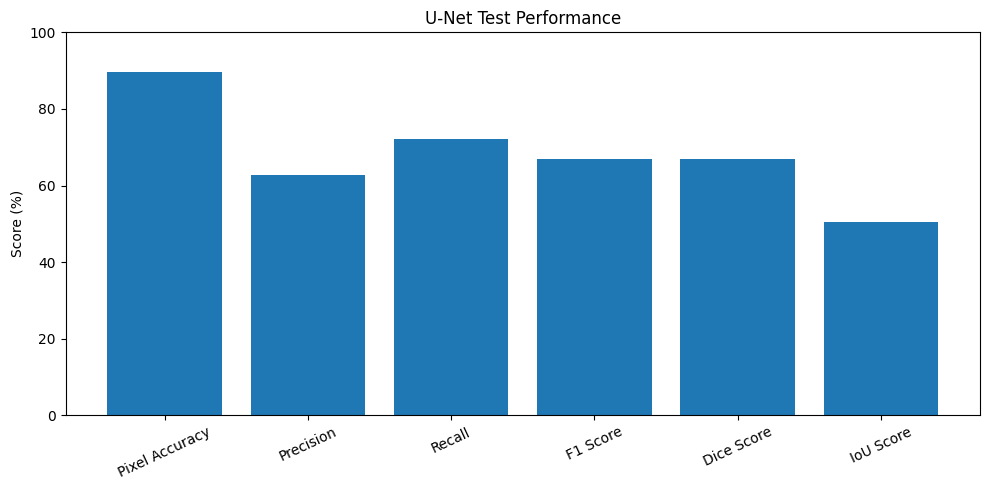

In [22]:
import matplotlib.pyplot as plt

metrics = {
    "Pixel Accuracy": 89.68,
    "Precision": 62.67,
    "Recall": 72.07,
    "F1 Score": 67.04,
    "Dice Score": 67.04,
    "IoU Score": 50.42
}

plt.figure(figsize=(10, 5))
plt.bar(metrics.keys(), metrics.values())

plt.title("U-Net Test Performance")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()